In [1]:
import os, sys
os.chdir("..")                 # run from the project root
sys.path.insert(0, os.getcwd())

import pandas as pd
import matplotlib.pyplot as plt
from models.text_pre_processor import preprocess_text, STOP_WORDS

df = pd.read_csv("datasets/sample1.csv")
df["text"] = (df["issue_title"].fillna("") + " " + df["issue_body"].fillna("")).str.strip()
df["processed"] = pd.read_pickle("datasets/cache/processed_text.pkl")

Q1: How many rows? Are there missing titles or bodies? What's the label balance?

(72289, 9)
issue_url                      0
issue_label                    0
issue_created_at               0
issue_author_association       0
repository_url                 0
issue_title                    0
issue_body                  7148
text                           0
processed                   6026
dtype: int64


<Axes: title={'center': 'Label Distribution'}, xlabel='Label', ylabel='Proportion'>

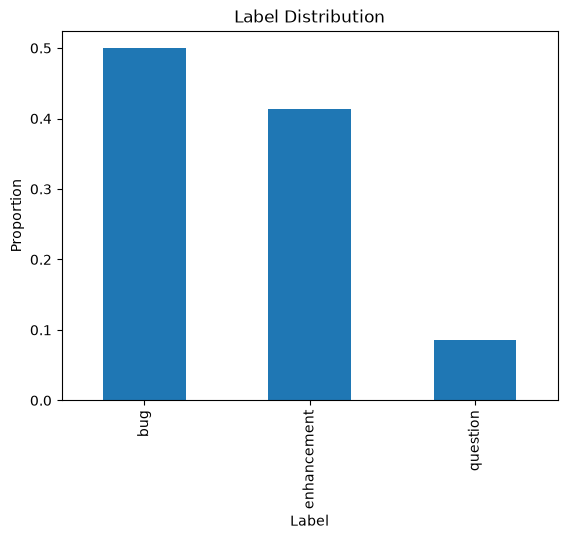

In [2]:
print(df.shape)
print(df.isna().sum())
label_balance = df['issue_label'].value_counts(normalize=True)
label_balance.plot(kind='bar', title='Label Distribution', ylabel='Proportion', xlabel='Label')

Answer: There are 72289 rows, only 7148 rows are missing in the issue_body column. 6026 rows are missing in the processed column. The label distribution is heavily dominated by the bug and enhancement labels with more than 90% of the total, while questions make up for roughly 9% of the total labels, making it an underrepresented class.

Q2: Are questions shorter or longer than bugs?

In [3]:
df["text"].str.split().str.len().groupby(df["issue_label"]).describe()

,count,mean,std,min,25%,50%,75%,max
issue_label,,,,,,,,
bug,36110.0,138.142703,366.657715,1.0,29.0,71.0,147.0,15448.0
enhancement,29937.0,59.528777,114.168308,1.0,13.0,32.0,71.0,8613.0
question,6242.0,138.478533,371.663038,1.0,38.0,78.0,148.0,13467.0


Answer: The length of questions is very similiar to bugs (138 words on average). Meanwhile the enhancement labelled texts are signigicantly shorter (59 words on average).

Q3. Duplicates: Are there identical issues? Identical issues with different labels?

In [4]:
# 3.1 Number of duplicate texts
df.duplicated(subset=["text"]).sum()

1124

In [5]:
# 3.2 One row per duplicated text: how many copies, which labels, how many repositories
dup_rows = df[df.duplicated(subset=["text"], keep=False)]
groups = dup_rows.groupby("text").agg(
    copies=("issue_label", "size"),
    labels=("issue_label", lambda s: sorted(set(s))),
    repos=("repository_url", "nunique"),
)
print(f"{len(dup_rows)} rows share their text with another row: {len(groups)} distinct texts, "
      f"{df.duplicated(subset=['text']).sum()} extra copies")

# The most-copied texts
(groups.assign(text=groups.index.str.slice(0, 80))
       .sort_values("copies", ascending=False)
       .head(10)
       .reset_index(drop=True)
       .style.hide(axis="index")
       .set_properties(subset=["text"], **{"text-align": "left"}))

1680 rows share their text with another row: 556 distinct texts, 1124 extra copies


copies,labels,repos,text
30,"['bug', 'enhancement', 'question']",30,"Getting Started with GitHub # :wave: Welcome to GitHub Learning Lab's ""Introduct"
25,['bug'],23,ISSUE 1: Corrección de páginas 5 y 3 ### Identificador de corrección: `FIX1` #
24,['bug'],24,ISSUE 1: Agregar nueva receta ### Identificador la acción: STEP1 Se han asign
22,['bug'],21,ISSUE 1: Corrección de páginas 5 y 3 ### Identificador de corrección: `FIX1`
20,['enhancement'],20,Contact Form for Reach Out Section # Contact Form for Reach Out Section ## Co
19,['bug'],19,ISSUE 2: Corrección de páginas 1 y 4 ### Identificador de corrección: `FIX2`
18,['enhancement'],18,Updates for Hero Section # Updates for Hero Section ## Content Requirement
18,['bug'],2,IR Accrued
16,['bug'],16,ISSUE 3: Corrección de página 2 ### Identificador de corrección: `FIX3` Recu
16,['bug'],16,ISSUE 2: Merge de correcciones de las páginas 3 y 5 ### Identificador del error


In [6]:
# 3.3 Same text, different labels = label noise
conflicting = groups[groups["labels"].str.len() > 1]
print(f"{len(conflicting)} texts ({conflicting['copies'].sum()} rows) carry more than one label")
conflicting["labels"].astype(str).value_counts().rename("texts")

112 texts (300 rows) carry more than one label


labels
['bug', 'enhancement']                53
['enhancement', 'question']           26
['bug', 'question']                   26
['bug', 'enhancement', 'question']     7
Name: texts, dtype: int64

In [7]:
# 3.4 Leakage: do validation/test issues also appear in the training set?
# Same filtering and split as train.py, on the processed text the model actually sees
from sklearn.model_selection import train_test_split

kept = df[df["processed"].notna()]
X_train, X_rest, y_train, y_rest = train_test_split(
    kept["processed"], kept["issue_label"], test_size=0.3, random_state=42, stratify=kept["issue_label"]
)
X_val, X_test, _, _ = train_test_split(X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest)

train_texts = set(X_train)
for name, X in [("validation", X_val), ("test", X_test)]:
    leaked = X.isin(train_texts)
    print(f"{name}: {leaked.sum()} of {len(X)} issues ({leaked.mean():.1%}) also appear in train")

validation: 262 of 9939 issues (2.6%) also appear in train
test: 268 of 9940 issues (2.7%) also appear in train


**Answer:** yes, there are both kinds.
- **1,124 extra copies** of 556 distinct texts (1,680 rows involved). Most are not real bug reports but **templates**: GitHub's "Getting Started with GitHub" tutorial issue (30 copies in 30 repositories, labeled bug, enhancement *and* question), course assignments ("ISSUE 1: Corrección de páginas…") and website-building tasks ("Contact Form for Reach Out Section").
- **112 texts (300 rows) carry conflicting labels**, mostly bug vs. enhancement (53). 59 involve `question`. No model can get these all right, so they put a ceiling on the score.
- **Leakage:** 2.6% of validation and 2.7% of test issues have an identical (processed) copy in the training set. The model has effectively seen their answer, so the current scores are slightly too optimistic.

→ **Change:** drop exact duplicates *before* splitting, and drop conflicting texts entirely.

Q4: Does issue_author_association (OWNER, CONTRIBUTOR, NONE…) differ by label?

In [8]:
# Share of each label per author type (rows sum to 1), plus how many issues each type wrote
author = pd.crosstab(df["issue_author_association"], df["issue_label"], normalize="index").round(3)
author["n_issues"] = df["issue_author_association"].value_counts()
author.sort_values("question", ascending=False)

issue_label,bug,enhancement,question,n_issues
issue_author_association,,,,
NONE,0.578,0.235,0.187,27147
CONTRIBUTOR,0.535,0.427,0.038,11254
COLLABORATOR,0.516,0.456,0.028,8900
MEMBER,0.479,0.498,0.024,8809
OWNER,0.346,0.637,0.017,16179


**Answer:** yes, and strongly for `question`. Issues by outsiders (`NONE`) are questions 18.7% of the time, against 2–4% for owners, members and contributors. Owners mostly file enhancements (64%).

The model can't use this as a feature today, because the API only receives title and body. It's still worth knowing: a real ticket system (Jira, GitHub) does know who reported an issue.

Q5: 6,026 issues became None. Do they share a label? Are they really non-English?       

In [9]:
# 5.1 Is the filter biased towards one label?
filtered = df[df["processed"].isna()]
pd.DataFrame({
    "share of filtered issues": filtered["issue_label"].value_counts(normalize=True),
    "share of all issues": df["issue_label"].value_counts(normalize=True),
    "% of this label filtered out": df["processed"].isna().groupby(df["issue_label"]).mean(),
}).style.format("{:.1%}")

,share of filtered issues,share of all issues,% of this label filtered out
issue_label,,,
bug,43.1%,50.0%,7.2%
enhancement,50.7%,41.4%,10.2%
question,6.2%,8.6%,6.0%


In [10]:
# 5.2 Read them: label + the first 200 characters of the text
def show_text(frame, n_chars=200):
    """Readable view of issues: label and a cut-off, single-line text."""
    view = pd.DataFrame({
        "label": frame["issue_label"],
        "text": frame["text"].str.replace(r"\s+", " ", regex=True).str.slice(0, n_chars),
    })
    return (view.style.hide(axis="index")
                .set_properties(**{"text-align": "left", "white-space": "normal"})
                .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

show_text(filtered.sample(15, random_state=0))

label,text
bug,Windows版で「タイルを2倍幅で表示」、グラフィクス「なし」の描画が従来に比べて遅い alpha24、「タイルを2倍幅で表示」、グラフィクス「なし」でプレイしていますが、alpha21でプレイしていた頃に比べてメインウィンドウの描画処理やサブウィンドウのメッセージ送りが従来より遅い気がします。 @が移動するとき、敵を倒したとき、店でアイテムを売ったときなどに、処理が完了するまで僅かにウェイトが
enhancement,Production mode No metadata updates. Problem freeze metadata
enhancement,ガントチャートビュー **Describe the feature you'd like / 機能する機能の説明を行ってください** ＞カレンダービューの様に、日付項目をガントチャートで表現できるビューがあると良い A clear and concise description of what you want to happen. / あなたが何をしたいのかについての、明確で簡潔な説明を行ってく
enhancement,[SAFEGUARD] 判断 node 版本 根据 `engines.node` 判断
bug,WeatherController 파라미터 에러 # WeatherController 파라미터 에러 ## 개요 keyword로 지역 검색 시 파라미터에서 발생한 에러를 검출하지 못했습니다. ### 발생 환경 - Ios ### 기대 내용 - 잘못된 요청이 왔을 때 클라이언트에게 메세지를 보내줍니다. ### 현재 내용 - 클라이언트가 요청에 대한 반환값을 받지 못
enhancement,"Incorporar categoría en ""Programas"" de Sacc 2 Estimados: Junto con saludar, solicito por favor incorporar en el ítem de creación de programa las siguientes categorías: Proyecto Diversos- MASSO Proyect"
bug,"""Gestaltung Sterne"" to be fixed"
enhancement,Agregar Notificaciones Investigar como enviar notificaciones a través de servicio web e implementarlo para solicitud de amigo y para localización.
bug,"Método ativaEfeito() de CartaMagica não foi implementado Nas clases `Game`, `GameOnline`, `Player` e `AED1` é chamado o método `ativaEfeito()` da classe `CartaMagica`. Este método, no entanto, ainda n"
enhancement,[Feature request] 기자와 기사 모델 관계 맺기 ## 내용 현재 기자와 기사가 따로 놀고 있는 문제가 있습니다. 기자와 기사를 연결시키는 작업을 하도록 하겠습니다. 기자는 has many 로 기사를 갖습니다. 기사는 기자에 belongs to 됩니다. 기자는 0개 이상의 기사를 가질 수 있고 기사는 반드시 한 명의 기사에게 belong 되어야


In [11]:
# 5.3 Text that uses only plain a–z letters is a candidate for wrongly filtered English.
# (German, Dutch or Italian without accents also passes, so read the sample.)
def ascii_letter_share(text):
    letters = [c for c in text if c.isalpha()]
    return sum(c.isascii() for c in letters) / len(letters) if letters else 0

ascii_only = filtered[filtered["text"].map(ascii_letter_share) >= 0.99]
print(f"{len(ascii_only)} of {len(filtered)} filtered issues ({len(ascii_only) / len(filtered):.0%}) use only a–z letters")
show_text(ascii_only.sample(12, random_state=0), n_chars=110)

2217 of 6026 filtered issues (37%) use only a–z letters


label,text
question,SQL Error [08006]: An I/O error occurred while sending to the backend. #### System information: - Windows 10 E
bug,Big-map BCD links point to delphinet
enhancement,"Gérer les touches du clavier Créer une énum pour gérer les touches du clavier : ```cpp KEY_ESCAPE, KEY_BACKSPA"
enhancement,"Karten ins UI Integrieren Als Team und UI Designer wünschen wir uns, dass die Karten in das UI integriert werd"
bug,Eine Session muss immer anhand des LoginNames gesucht werden https://github.com/FAP-Cloud-Service/FAP-Backend/
bug,Upravit CSS pro korektni zobrazeni clanku na uvodni strance.
enhancement,"Add primary content (e.g. avatar, name, job, contacts, intro, etc.)"
bug,Ladenpreise werden teils nicht gespeichert **Character Name** Glinda Ehrmantraut **Auftrittszeitpunkt (Datum /
bug,Voorkomen dat twee keer op 'opvoeren' geklikt kan worden bij opvoeren van sensor
bug,Incompatibilità con PHP 8 (2.4.x) Magari è utile avere un issue in cui segnalare eventuali incompatibilità con


**Answer:** the filter is mostly right, but it makes two kinds of mistakes.
- **Bias:** it isn't biased *against* questions (6% of questions are filtered, against 7% of bugs). But it removes enhancements more often (10%). Many non-English issues are student or course projects, which mostly file feature tasks.
- **Correctness:** 63% of the filtered issues contain letters outside a–z (Japanese, Korean, Russian, accented Spanish…), and those are genuinely non-English. Among the other 2,217 that use only a–z letters, many are English. The random sample in 5.2 already shows one: "Production mode No metadata updates…". In the 12 shown in 5.3, 5 are clearly English: "SQL Error [08006]…", "Big-map BCD links point to delphinet", "Add primary content (e.g. avatar, name…)", "Fix session -> session.user", "Add some pterosaurus!". Short, technical English with code or names confuses `langdetect`.

That's lost training data. Worse, the **API rejects those same English users with a 400 error** ("Input is not in English").

→ **Change:** make the filter less aggressive, e.g. only reject when `langdetect` is confident (`detect_langs` probability), or when most letters are non-Latin. Then measure how many English issues come back.

Q6: Read 30 question issues, raw vs. processed side by side. 

1. Print issue_title next to preprocess_text(issue_title) for 30 questions.
2. Compute the share of raw questions vs. raw bugs whose text contains "?".
3. Check whether "how", "what" and "why" are in STOP_WORDS.

Does the model ever get to see those signals.

In [12]:
# 6.1 Raw title vs. what the model actually sees
LABEL_COLORS = {"bug": "#2a78d6", "enhancement": "#eb6834", "question": "#1baf7a"}

questions = df[df["issue_label"] == "question"].sample(30, random_state=0)
side_by_side = pd.DataFrame({
    "raw title": questions["issue_title"].str.slice(0, 90),
    "processed title": questions["issue_title"].apply(preprocess_text),
})

(side_by_side.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left", "white-space": "normal"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .format(na_rep="None (filtered out)"))

raw title,processed title
Command System Overhaul,command system overhaul
Deploying freqtrade dockers on Azure Container Instances (ACI),deploying freqtrade docker azure container instance aci
How to get type information of CallExpressions?,get type information callexpressions
How to add All price types in my product detail for choosing it?,add price type product detail choosing
Add a possibility to find SelenideElements inside SelenideElements,None (filtered out)
How to change normalization context for action,change normalization context action
Time frame for 4.2 release?,time frame release
Enrichissement du mise en style des commentaires,None (filtered out)
How do I activate several springs at the same time?,activate several spring time
GAM 360 issue,gam issue


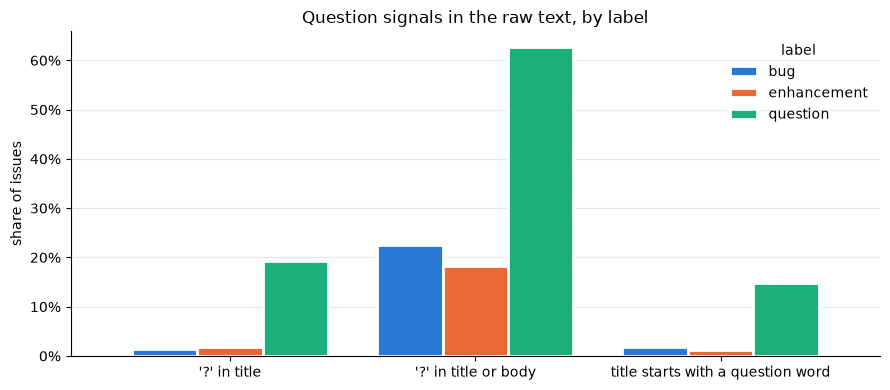

,'?' in title,'?' in title or body,title starts with a question word
issue_label,,,
bug,1.4%,22.6%,1.8%
enhancement,1.8%,18.2%,1.1%
question,19.2%,62.8%,14.7%


In [13]:
# 6.2 How common are question signals in the raw text, per label?
question_words = r"\s*(?:how|what|why|where|when|which|is|are|can|does|do|should)\b"
signals = pd.DataFrame({
    "'?' in title": df["issue_title"].str.contains("?", regex=False),
    "'?' in title or body": df["text"].str.contains("?", regex=False),
    "title starts with a question word": df["issue_title"].str.lower().str.match(question_words),
}).groupby(df["issue_label"]).mean()

ax = signals.T.plot.bar(rot=0, figsize=(9, 4), width=0.8, edgecolor="white", linewidth=2,
                        color=[LABEL_COLORS[c] for c in signals.index])
ax.set_ylabel("share of issues")
ax.set_title("Question signals in the raw text, by label")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(title="label", frameon=False)
plt.tight_layout()
plt.show()

signals.style.format("{:.1%}")

In [14]:
# 6.3 Do these signals survive preprocessing?
words = ["how", "what", "why", "where", "when", "which", "can", "does", "is", "should", "not", "no"]
print({w: w in STOP_WORDS for w in words})
print("'?' kept after preprocessing:", df["processed"].str.contains("?", regex=False).any())

{'how': True, 'what': True, 'why': True, 'where': True, 'when': True, 'which': True, 'can': True, 'does': True, 'is': True, 'should': True, 'not': True, 'no': True}
'?' kept after preprocessing: False


**Answer:** questions do have clear surface signals.
- **63%** of questions contain a `?`, against 22% of bugs and 18% of enhancements. In titles the gap is even bigger: 19% vs 1–2%.
- **15%** of question titles start with a question word (how, what, why…), against 1–2% for the other labels.

**Preprocessing deletes all of these.** `remove_noise` strips `?` together with all other punctuation, and every question word is an NLTK stopword. Negations (`not`, `no`) are stopwords too. So "How to change normalization context for action" reaches the model as "change normalization context action", which reads like a feature request. This is likely a main cause of the 0.15 question recall, which step 4 will test by keeping these signals.

**Side finding:** several clearly English titles come back as `None`, e.g. "Add a possibility to find SelenideElements inside SelenideElements". The language check (langdetect, 5+ words) misfires on short, technical English. That makes this question 5's problem too: the 6,026 filtered issues likely include English ones.

## Findings

Each finding: **what the data shows → what I'll change → when**.

1. **Leakage:** 2.6% of validation and 2.7% of test issues have an identical (processed) copy in train, so the current scores are slightly optimistic.
   → Remove exact duplicates *before* splitting. *(Now, before step 3)*
2. **Label noise:** 112 texts (300 rows) appear with conflicting labels; 59 of them involve `question`. No model can classify these consistently.
   → Drop conflicting texts entirely. *(Now, before step 3)*
3. **Templates:** most of the 1,124 duplicate copies are templates, not real tickets: GitHub's tutorial issue (30×, with all three labels), course assignments, website tasks.
   → Removed by findings 1–2. Keep in mind that the dataset also contains student projects, not only production software. *(Now)*
4. **Class imbalance:** only 8.6% of issues are questions. The Random Forest already uses `class_weight="balanced"` and still reaches only 0.15 question recall, so weighting alone is not enough.
   → Compare class weighting and tune the decision threshold for `question` on the validation set. *(Step 5)*
5. **Question signals are removed:** 63% of questions contain a `?` (bugs: 22%) and 15% of question titles start with a question word (others: 1–2%). Preprocessing removes `?`, all question words and negations (`not`, `no`) as stopwords. This is likely a main cause of the 0.15 question recall, to be confirmed by measuring.
   → Keep `?` as a token and use a custom stopword list that keeps question words and negations. *(Step 4)*
6. **Questions look like bugs, not enhancements:** questions and bugs have the same length (median 78 vs 71 words; enhancements 32), and 450 of 880 missed questions were predicted as bug, against 299 as enhancement.
   → After step 4, check whether bug ↔ question confusion drops; study the remaining errors. *(Steps 4 and 6)*
7. **Language filter is too aggressive:** it removes 6,026 issues (8.3%). Of the 2,217 that use only a–z letters, many are English (5 of the 12 sampled). The same check makes the API reject English users with a 400 error.
   → Only reject text when `langdetect` is confident, or when most letters are non-Latin; measure how many issues come back. *(Step 4)*
8. **Who writes questions:** 18.7% of issues from outsiders (`NONE`) are questions, against 2–4% for owners, members and contributors. This is the strongest question signal in the data, but the API only receives title and body.
   → Out of scope for now.